In [1]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

sns.set()
%config InlineBackend.figure_format = 'retina'

In [4]:
zip_path = 'flights_2008.csv.bz2'

In [5]:
columns = [
    'DayOfWeek', 'DayofMonth', 'Month', 'Cancelled', 'Year', 'FlightNum', 'Distance',
    'UniqueCarrier', 'CancellationCode', 'Origin', 'Dest', 'ArrDelay', 'DepDelay',
    'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay',
    'DepTime'
]

dtypes = {
    "DayOfWeek": np.uint8,
    "DayofMonth": np.uint8,
    "Month": np.uint8,
    "Cancelled": np.uint8,
    "Year": np.uint16,
    "FlightNum": np.uint16,
    "Distance": np.uint16,
    "UniqueCarrier": "category",
    "CancellationCode": "category",
    "Origin": "category",
    "Dest": "category",
    "ArrDelay": np.float32,
    "DepDelay": np.float32,
    "CarrierDelay": np.float32,
    "WeatherDelay": np.float32,
    "NASDelay": np.float32,
    "SecurityDelay": np.float32,
    "LateAircraftDelay": np.float32,
    "DepTime": np.float32
}

In [6]:
# Чтение данных
df = pd.read_csv(zip_path, usecols=columns)

In [7]:
# Быстрый просмотр
df.head()

,Year,Month,DayofMonth,DayOfWeek,DepTime,UniqueCarrier,FlightNum,ArrDelay,DepDelay,Origin,Dest,Distance,Cancelled,CancellationCode,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2008,1,3,4,2003.0,WN,335,-14.0,8.0,IAD,TPA,810,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2008,1,3,4,754.0,WN,3231,2.0,19.0,IAD,TPA,810,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2008,1,3,4,628.0,WN,448,14.0,8.0,IND,BWI,515,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2008,1,3,4,926.0,WN,1746,-6.0,-4.0,IND,BWI,515,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2008,1,3,4,1829.0,WN,3920,34.0,34.0,IND,BWI,515,0,NaN,2.0,0.0,0.0,0.0,32.0


In [8]:
df.shape

(7009728, 19)

In [9]:
df.isnull().sum()

Year                       0
Month                      0
DayofMonth                 0
DayOfWeek                  0
DepTime               136246
UniqueCarrier              0
FlightNum                  0
ArrDelay              154699
DepDelay              136246
Origin                     0
Dest                       0
Distance                   0
Cancelled                  0
CancellationCode     6872294
CarrierDelay         5484993
WeatherDelay         5484993
NASDelay             5484993
SecurityDelay        5484993
LateAircraftDelay    5484993
dtype: int64

In [10]:
df['UniqueCarrier'].unique()

array(['WN', 'XE', 'YV', 'OH', 'OO', 'UA', 'US', 'DL', 'EV', 'F9', 'FL',
       'HA', 'MQ', 'NW', '9E', 'AA', 'AQ', 'AS', 'B6', 'CO'], dtype=object)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7009728 entries, 0 to 7009727
Data columns (total 19 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Year               int64  
 1   Month              int64  
 2   DayofMonth         int64  
 3   DayOfWeek          int64  
 4   DepTime            float64
 5   UniqueCarrier      object 
 6   FlightNum          int64  
 7   ArrDelay           float64
 8   DepDelay           float64
 9   Origin             object 
 10  Dest               object 
 11  Distance           int64  
 12  Cancelled          int64  
 13  CancellationCode   object 
 14  CarrierDelay       float64
 15  WeatherDelay       float64
 16  NASDelay           float64
 17  SecurityDelay      float64
 18  LateAircraftDelay  float64
dtypes: float64(8), int64(7), object(4)
memory usage: 1016.1+ MB


In [12]:
df.describe()

,Year,Month,DayofMonth,DayOfWeek,DepTime,FlightNum,ArrDelay,DepDelay,Distance,Cancelled,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
count,7009728.0,7.009728e+06,7.009728e+06,7.009728e+06,6.873482e+06,7.009728e+06,6.855029e+06,6.873482e+06,7.009728e+06,7.009728e+06,1.524735e+06,1.524735e+06,1.524735e+06,1.524735e+06,1.524735e+06
mean,2008.0,6.375130e+00,1.572801e+01,3.924182e+00,1.333830e+03,2.224200e+03,8.168452e+00,9.972570e+00,7.263870e+02,1.960618e-02,1.577206e+01,3.039031e+00,1.716462e+01,7.497434e-02,2.077098e+01
std,0.0,3.406737e+00,8.797068e+00,1.988259e+00,4.780689e+02,1.961716e+03,3.850194e+01,3.531127e+01,5.621018e+02,1.386426e-01,4.009912e+01,1.950287e+01,3.189495e+01,1.837940e+00,3.925964e+01
min,2008.0,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,-5.190000e+02,-5.340000e+02,1.100000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,2008.0,3.000000e+00,8.000000e+00,2.000000e+00,9.280000e+02,6.220000e+02,-1.000000e+01,-4.000000e+00,3.250000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2008.0,6.000000e+00,1.600000e+01,4.000000e+00,1.325000e+03,1.571000e+03,-2.000000e+00,-1.000000e+00,5.810000e+02,0.000000e+00,0.000000e+00,0.000000e+00,6.000000e+00,0.000000e+00,0.000000e+00
75%,2008.0,9.000000e+00,2.300000e+01,6.000000e+00,1.728000e+03,3.518000e+03,1.200000e+01,8.000000e+00,9.540000e+02,0.000000e+00,1.600000e+01,0.000000e+00,2.100000e+01,0.000000e+00,2.600000e+01
max,2008.0,1.200000e+01,3.100000e+01,7.000000e+00,2.400000e+03,9.743000e+03,2.461000e+03,2.467000e+03,4.962000e+03,1.000000e+00,2.436000e+03,1.352000e+03,1.357000e+03,3.920000e+02,1.316000e+03


In [13]:
df["UniqueCarrier"].nunique()

20

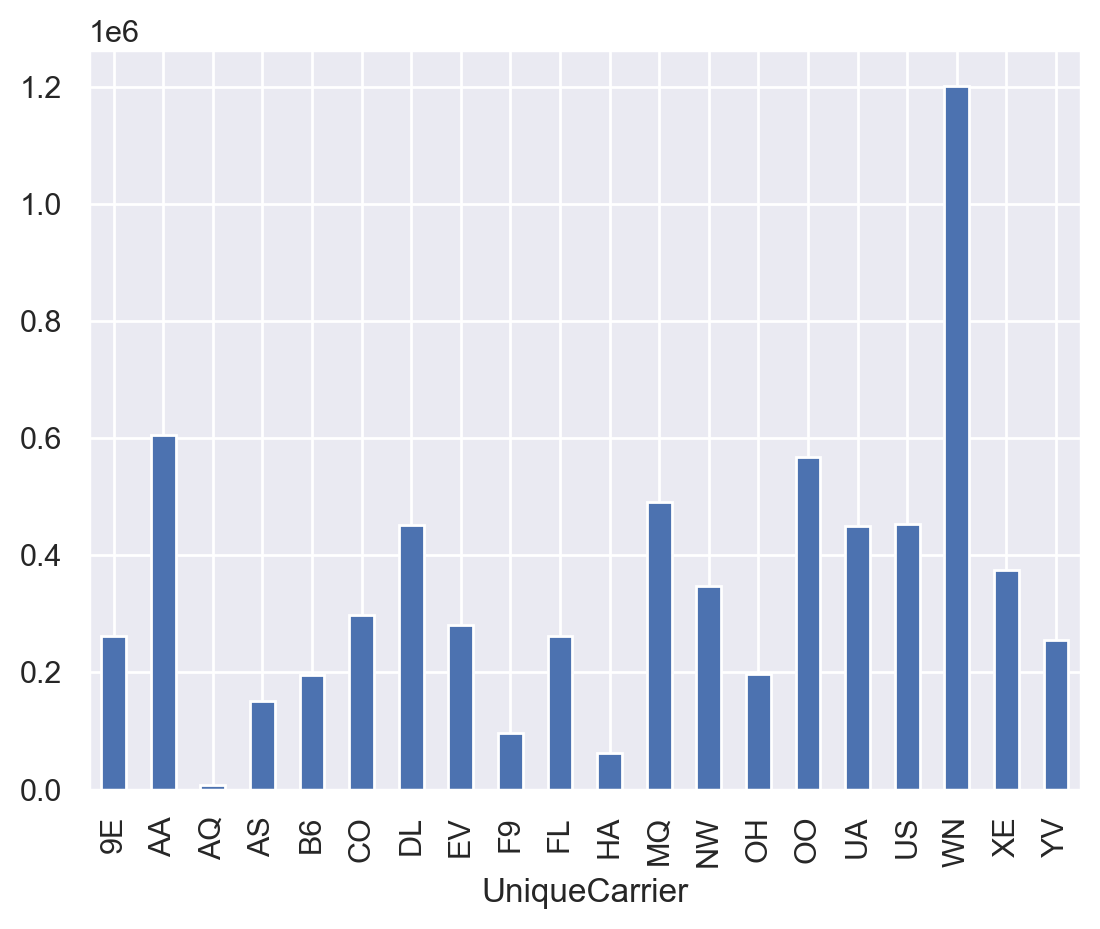

In [14]:
# Количество рейсов по перевозчикам 
df.groupby("UniqueCarrier").size().plot(kind="bar");

In [15]:
# поиск топ-3 кодов рейсов с наибольшим общим расстоянием, пройденным в 2008 году.
df.groupby(["UniqueCarrier", "FlightNum"])["Distance"].sum().sort_values(ascending=False).iloc[:3]

UniqueCarrier  FlightNum
CO             15           1796244
               14           1796244
UA             52           1789722
Name: Distance, dtype: int64

In [16]:
df.groupby(["UniqueCarrier", "FlightNum"]).agg({"Distance": [np.mean, np.sum, "count"], "Cancelled": np.sum}
).sort_values(("Distance", "sum"), ascending=False).iloc[0:3]

/var/folders/h5/nn_z0fbd4099gxgkjqyqmtvr0000gn/T/ipykernel_35647/2430302656.py:1: FutureWarning: The provided callable <function mean at 0x109e6e8e0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  df.groupby(["UniqueCarrier", "FlightNum"]).agg({"Distance": [np.mean, np.sum, "count"], "Cancelled": np.sum}
/var/folders/h5/nn_z0fbd4099gxgkjqyqmtvr0000gn/T/ipykernel_35647/2430302656.py:1: FutureWarning: The provided callable <function sum at 0x109e6d800> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  df.groupby(["UniqueCarrier", "FlightNum"]).agg({"Distance": [np.mean, np.sum, "count"], "Cancelled": np.sum}


Distance                Cancelled
                                mean      sum count       sum
UniqueCarrier FlightNum                                      
CO            15         4962.000000  1796244   362         0
              14         4962.000000  1796244   362         0
UA            52         2465.181818  1789722   726         8

In [17]:
# Количество рейсов по дням недели и месяцам:
pd.crosstab(df.Month,df.DayOfWeek)

DayOfWeek,1,2,3,4,5,6,7
Month,,,,,,,
1,80807,97298,100080,102043,81940,67178,76419
2,81504,79700,80587,82158,102726,66462,76099
3,103210,81159,82307,82831,82936,86153,97494
4,82463,100785,102586,82799,82964,68304,78225
5,80626,79884,81264,102572,102878,84493,74576
6,104168,82160,82902,83617,83930,72322,99566
7,84095,103429,103315,105035,79349,72219,80489
8,82983,80895,81773,82625,103878,86155,93970
9,94300,91533,74057,75589,75881,58343,71205


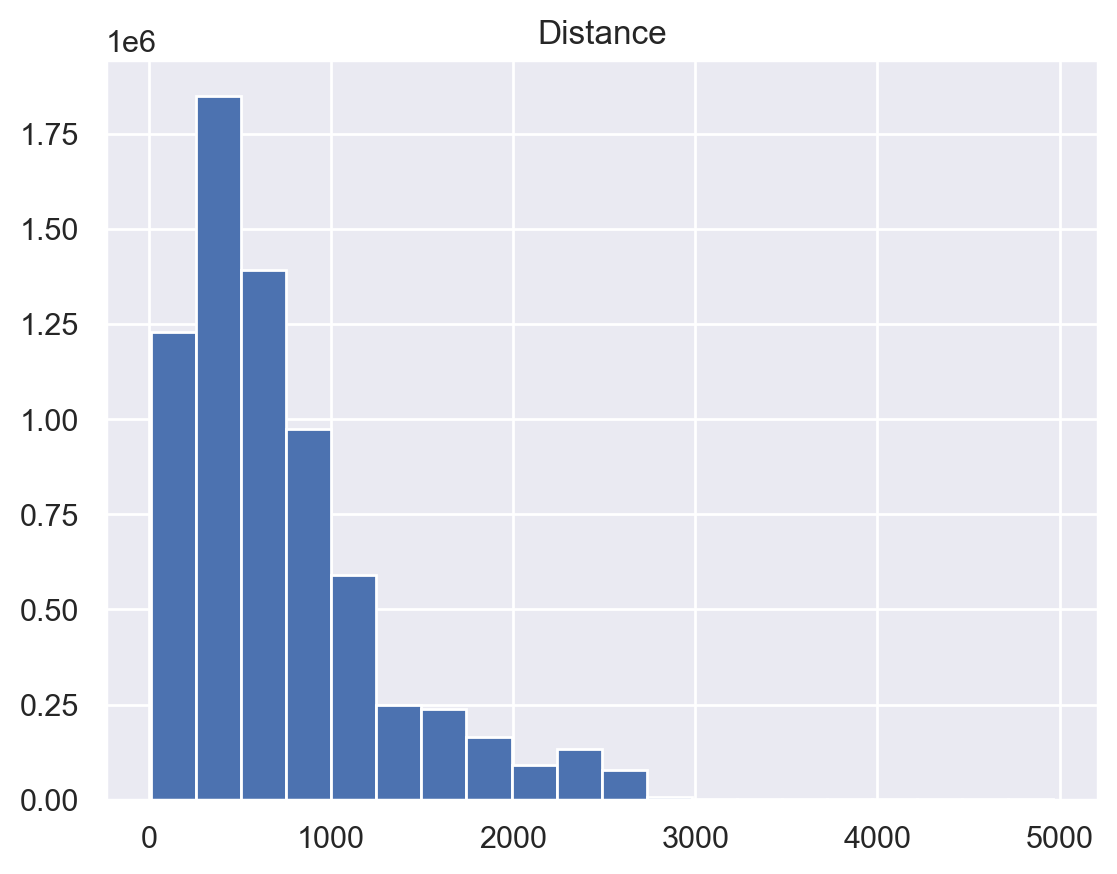

In [18]:
# Гистограмма дальности полета:
df.hist("Distance", bins=20);

In [19]:
# Составление гистограммы частоты рейсов по дате.
df["Date"] = pd.to_datetime(df.rename(columns={"DayofMonth": "Day"})[["Year", "Month", "Day"]])

In [20]:
num_flights_by_date = df.groupby("Date").size()

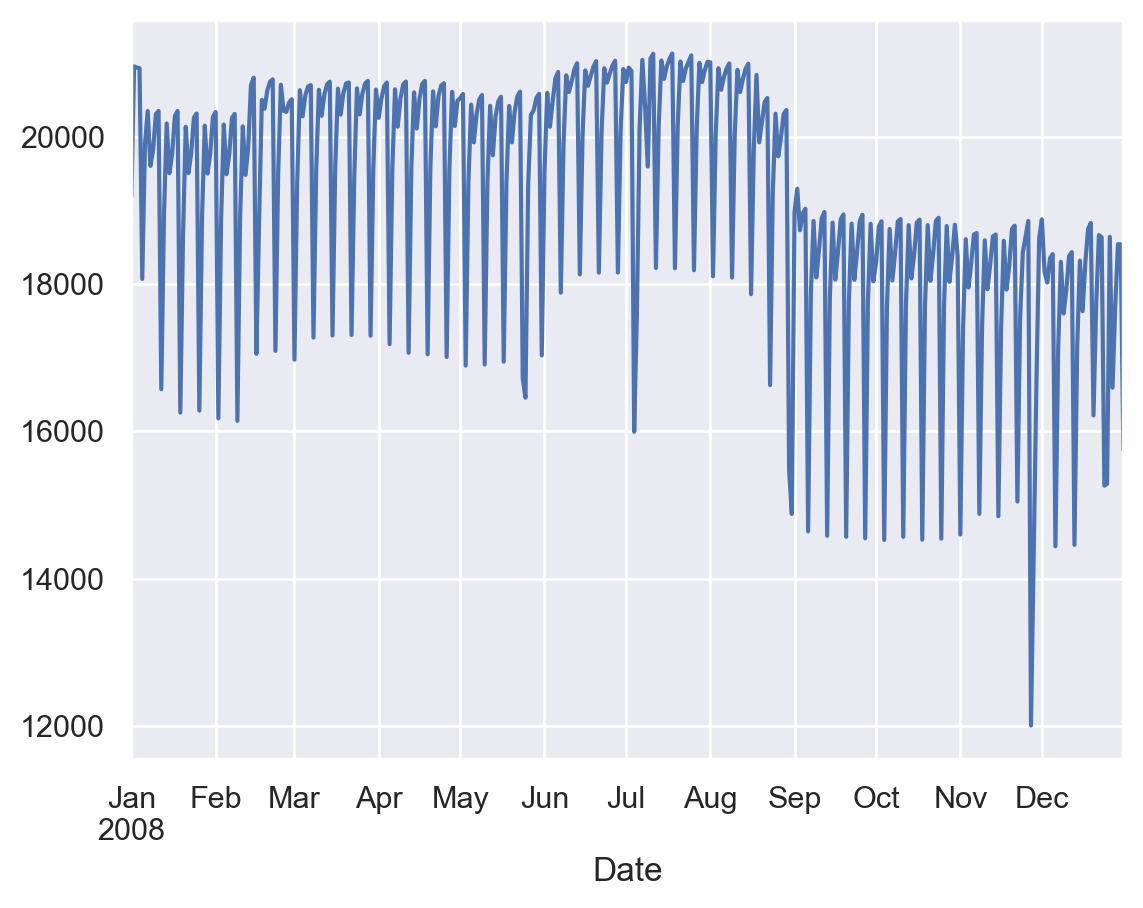

In [21]:
num_flights_by_date.plot();

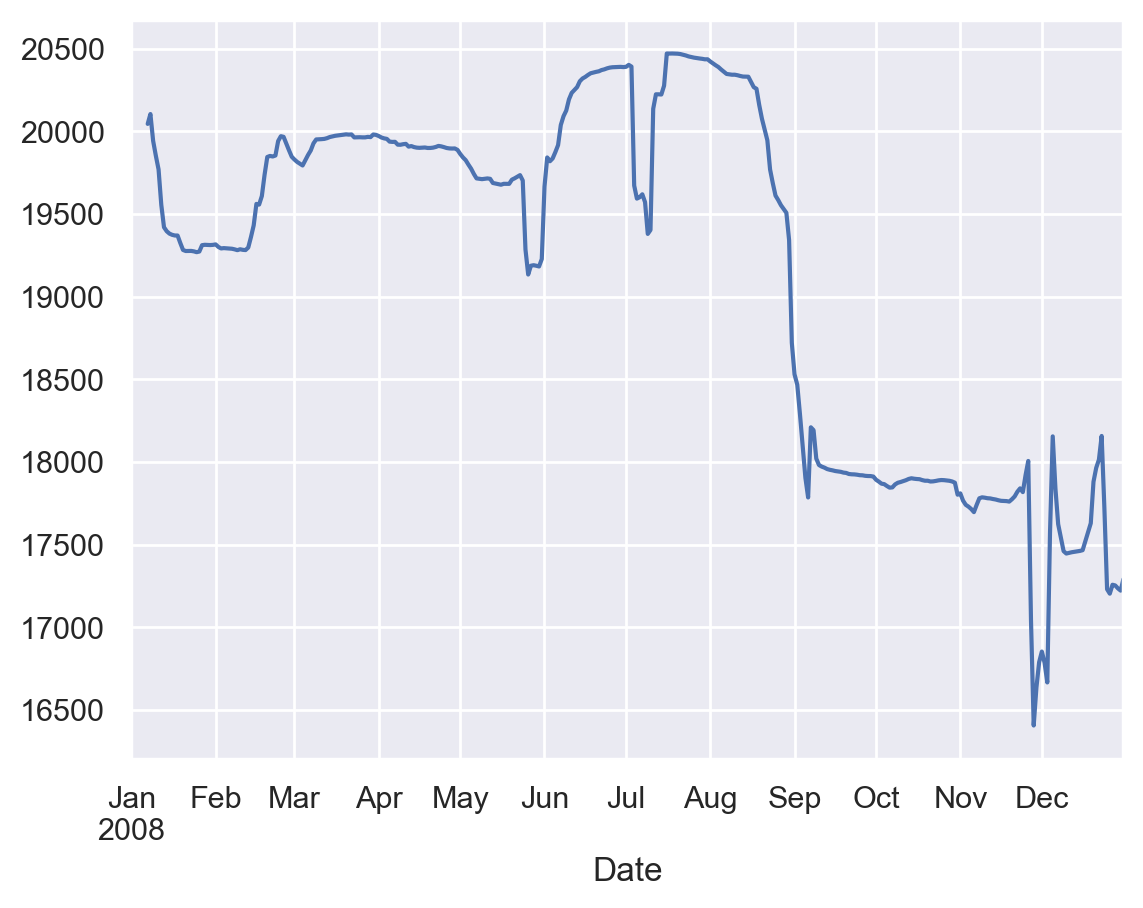

In [22]:
num_flights_by_date.rolling(window=7).mean().plot();

In [23]:
# Вопрос 1. Набор данных включает как отмененные, так и завершенные рейсы. Определите, есть ли больше выполненных или отмененных рейсов, и посчитайте числовую разницу между ними.

cancelled_flights = df['Cancelled'].sum()
completed_flights = len(df) - cancelled_flights
difference = completed_flights - cancelled_flights
if completed_flights > cancelled_flights:
    result = f"Выполнено рейсов больше, чем отменено на {difference}."
else:
    result = f"Отмененных рейсов больше, чем выполненных на {-difference}."
print(result)

Выполнено рейсов больше, чем отменено на 6734860.


In [28]:
# **Вопрос 2. Найдите рейс с наибольшей задержкой вылета и рейс с наибольшей задержкой прибытия. Летят ли они в один аэропорт, и если да, то какой у него код?**
# да, MSP

max_dep_delay_flight = df.loc[df['DepDelay'].idxmax()]
max_arr_delay_flight = df.loc[df['ArrDelay'].idxmax()]
same_destination = max_dep_delay_flight['Dest'] == max_arr_delay_flight['Dest']
destination_code = max_dep_delay_flight['Dest'] if same_destination else "не совпадают"
print(f"Рейс с наибольшей задержкой вылета:\n{max_dep_delay_flight}\n")
print(f"Рейс с наибольшей задержкой прибытия:\n{max_arr_delay_flight}\n")
print(f"Летят ли они в один аэропорт? {'Да' if same_destination else 'Нет'}, код аэропорта: {destination_code}")

Рейс с наибольшей задержкой вылета:
Year                                2008
Month                                  4
DayofMonth                            10
DayOfWeek                              4
DepTime                            724.0
UniqueCarrier                         NW
FlightNum                           1699
ArrDelay                          2453.0
DepDelay                          2467.0
Origin                               CLT
Dest                                 MSP
Distance                             930
Cancelled                              0
CancellationCode                     NaN
CarrierDelay                      2436.0
WeatherDelay                         0.0
NASDelay                             0.0
SecurityDelay                        0.0
LateAircraftDelay                   17.0
Date                 2008-04-10 00:00:00
Name: 2235378, dtype: object

Рейс с наибольшей задержкой прибытия:
Year                                2008
Month                              

In [30]:
# Вопрос 3. Найдите перевозчика, у которого наибольшее количество отмененных рейсов.
# MQ

cancelled_flights = df[df['Cancelled'] == 1]
cancelled_by_carrier = cancelled_flights['UniqueCarrier'].value_counts()
max_cancelled_carrier = cancelled_by_carrier.idxmax()
max_cancelled_count = cancelled_by_carrier.max()
print(f"Перевозчик с наибольшим количеством отмененных рейсов: {max_cancelled_carrier} ({max_cancelled_count} рейсов)")

Перевозчик с наибольшим количеством отмененных рейсов: MQ (18331 рейсов)


In [34]:
# Вопрос 4. Давайте рассмотрим время отправления и рассмотрим распределение по часам (столбец `DepHour`, который мы создали ранее). В какой час самый высокий процент рейсов?**
# Подсказка:* Проверьте формат времени [здесь](https://www.transtats.bts.gov/Fields.asp?gnoyr_VQ=FGJ).
# 8 am

df['DepHour'] = df['DepTime'].dropna().apply(lambda x: int(str(int(x)).zfill(4)[:2]) if not pd.isnull(x) else np.nan)
hourly_counts = df['DepHour'].value_counts(normalize=True).sort_index()
max_hour = hourly_counts.idxmax()
max_percentage = hourly_counts.max() * 100
print(f"Час с наибольшим процентом рейсов: {max_hour} ({max_percentage:.2f}%)")

Час с наибольшим процентом рейсов: 8.0 (6.54%)


In [36]:
# Вопрос 5. Хорошо, теперь давайте рассмотрим распределение отмененных рейсов по времени. В какой час наименьший процент отмененных рейсов?**
#  2 am

cancelled_flights = df[df['Cancelled'] == 1].groupby('DepHour').size()
total = cancelled_flights.sum()
cancelled_percentages = (cancelled_flights / total) * 100
least_cancelled_percentages = cancelled_percentages.idxmin()
print(f"Час с наименьшим процентом отмененных рейсов: {least_cancelled_percentages}")

Час с наименьшим процентом отмененных рейсов: 2.0


In [37]:
# Вопрос 6. Есть ли какой-нибудь час, в который вообще не было отмененных рейсов? Проверить все, что относится.**
# 3

df['DepHour'] = df['DepTime'].dropna().apply(lambda x: int(str(int(x)).zfill(4)[:2]) if not pd.isnull(x) else np.nan)
cancelled_flights = df[df['Cancelled'] == 1]
cancelled_hourly_counts = cancelled_flights['DepHour'].value_counts().sort_index()
hours_without_cancellations = [hour for hour in range(24) if hour not in cancelled_hourly_counts.index]
print(f"Часы без отмененных рейсов: {hours_without_cancellations}")

Часы без отмененных рейсов: [3]


In [38]:
# Вопрос 7. Найдите самый загруженный час или, другими словами, час, когда количество вылетающих рейсов достигает максимума.**
# Подсказка:* Учитывайте только *завершенные* рейсы.
#  8

df['DepHour'] = df['DepTime'].dropna().apply(lambda x: int(str(int(x)).zfill(4)[:2]) if not pd.isnull(x) else np.nan)
completed_flights = df[df['Cancelled'] == 0]
completed_hourly_counts = completed_flights['DepHour'].value_counts().sort_index()
busiest_hour = completed_hourly_counts.idxmax()
print("Самый загруженный час:", busiest_hour)

Самый загруженный час: 8.0


In [40]:
# Вопрос 8. Поскольку мы знаем час отправления, было бы интересно изучить среднюю задержку для соответствующего часа. Бывают ли случаи, когда самолеты в среднем вылетали раньше положенного? И если да, то в какое время это произошло?**
# Подсказка:* Учитывайте только *завершенные* рейсы.
# да, в 5-6 утра

df['DepHour'] = df['DepTime'].dropna().apply(lambda x: int(str(int(x)).zfill(4)[:2]) if not pd.isnull(x) else np.nan)
completed_flights = df[df['Cancelled'] == 0]
mean_delay_by_hour = completed_flights.groupby('DepHour')['DepDelay'].mean()
negative_delay_hours = mean_delay_by_hour[mean_delay_by_hour < 0]
if negative_delay_hours.empty:
    print("Нет случаев, когда самолеты в среднем вылетали раньше положенного.")
else:
    print("Случаи, когда самолеты в среднем вылетали раньше положенного, произошли в следующие часы:")
    print(negative_delay_hours)

Случаи, когда самолеты в среднем вылетали раньше положенного, произошли в следующие часы:
DepHour
5.0   -4.255584
6.0   -1.629400
Name: DepDelay, dtype: float64


In [42]:
# Вопрос 9. Учитывая только выполненные перевозчиком рейсы, которого вы нашли в вопросе 3, найдите распределение этих рейсов по часам. В какое время вылетает наибольшее количество самолетов?**
# в 10 утра

mq_completed_flights = df[(df['Cancelled'] == 0) & (df['UniqueCarrier'] == 'MQ')]
mq_completed_flights['DepHour'] = mq_completed_flights['DepTime'].dropna().apply(lambda x: int(str(int(x)).zfill(4)[:2]) if not pd.isnull(x) else np.nan)
hourly_flight_counts = mq_completed_flights['DepHour'].value_counts().sort_index()
busiest_hour = hourly_flight_counts.idxmax()
print("Наибольшее количество самолетов вылетает в", busiest_hour, "часов.")

Наибольшее количество самолетов вылетает в 10 часов.


/var/folders/h5/nn_z0fbd4099gxgkjqyqmtvr0000gn/T/ipykernel_35647/2249554524.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  mq_completed_flights['DepHour'] = mq_completed_flights['DepTime'].dropna().apply(lambda x: int(str(int(x)).zfill(4)[:2]) if not pd.isnull(x) else np.nan)


In [44]:
# Вопрос 10. Найдите топ-10 перевозчиков по количеству *выполненных* рейсов (столбец *UniqueCarrier*)?**
# Что из перечисленного ниже *нет* в вашем списке топ-10?**
# EV

completed_flights = df[df['Cancelled'] == 0]
carrier_flights = completed_flights['UniqueCarrier'].value_counts().sort_values(ascending=False)
top_carriers = carrier_flights.head(10)
print("Топ-10 перевозчиков по количеству выполненных рейсов:")
print(top_carriers)

carriers_to_check = ["DL", "AA", "OO", "EV"]
not_in_top_10 = [carrier for carrier in carriers_to_check if carrier not in top_carriers.index]
print("\nИз перечисленных перевозчиков в топ-10 нет:", not_in_top_10)

Топ-10 перевозчиков по количеству выполненных рейсов:
UniqueCarrier
WN    1189365
AA     587445
OO     554723
MQ     472362
US     447007
DL     445118
UA     438974
XE     364518
NW     344746
CO     294753
Name: count, dtype: int64

Из перечисленных перевозчиков в топ-10 нет: ['EV']


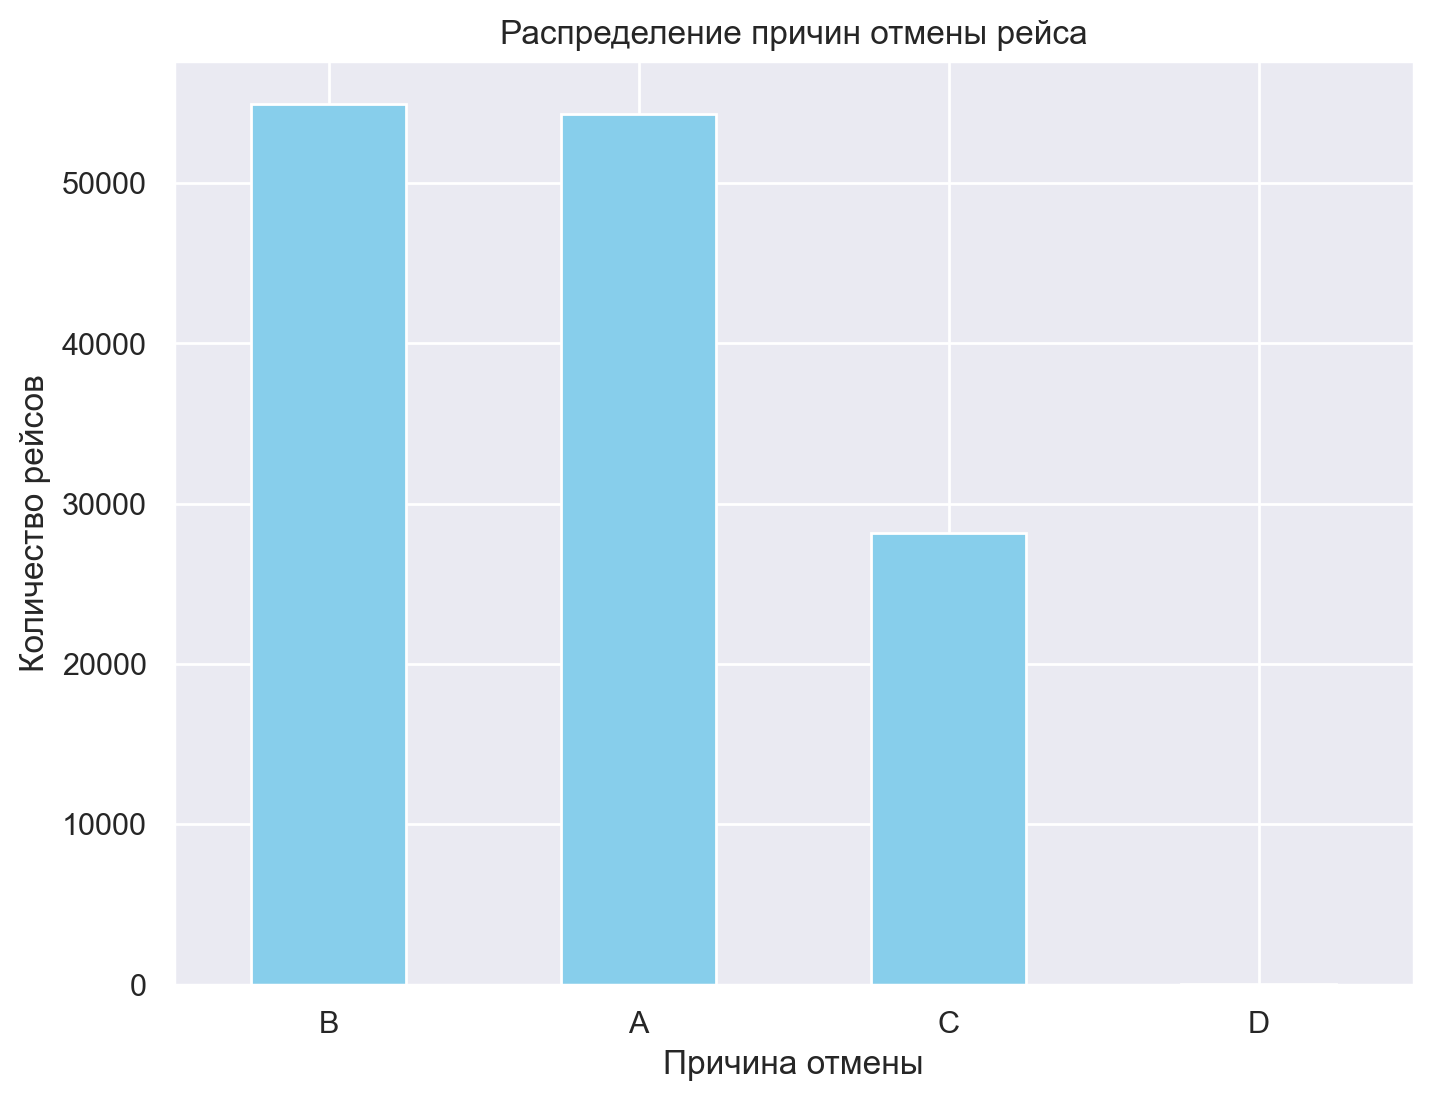

Наиболее частая причина отмены рейса: B


In [45]:
# Вопрос 11. Постройте распределение причин отмены рейса (CancellationCode).**
# Какая наиболее частая причина отмены рейса? (Используйте эту [ссылку](https://www.transtats.bts.gov/Fields.asp?Table_ID=236), чтобы перевести коды в причины)**
# Погодные условия - B

cancellation_reasons = df['CancellationCode'].value_counts()

plt.figure(figsize=(8, 6))
cancellation_reasons.plot(kind='bar', color='skyblue')
plt.title('Распределение причин отмены рейса')
plt.xlabel('Причина отмены')
plt.ylabel('Количество рейсов')
plt.xticks(rotation=0)
plt.show()

most_common_reason = cancellation_reasons.idxmax()
print("Наиболее частая причина отмены рейса:", most_common_reason)

In [46]:
# Вопрос 12. Какой маршрут наиболее частый по количеству рейсов?**
# (Обратите внимание на столбцы *'Origin'* и *'Dest'*. Рассматривайте направления *A->B* и *B->A* как *разные* маршруты)
# Сан-Франциско – Лос-Анджелес (SFO-LAX)

route_counts = df.groupby(['Origin', 'Dest']).size().sort_values(ascending=False)
most_common_route = route_counts.idxmax()
print("Наиболее частый маршрут по количеству рейсов:", most_common_route)

Наиболее частый маршрут по количеству рейсов: ('SFO', 'LAX')


In [50]:
# Вопрос 13. . Найдите топ-5 задержанных маршрутов (посчитайте, сколько раз они задерживались при отправлении). Из всех рейсов по этим 5 маршрутам посчитайте все рейсы, погодные условия которых способствовали задержке.**
# Подсказка*: учитывайте только положительные задержки
# 668

delayed_flights = df[df['DepDelay'] > 0].groupby(['Origin', 'Dest']).size().nlargest(5)
delayed_routes = df[df.set_index(['Origin', 'Dest']).index.isin(delayed_flights.index)]
weather_delays = delayed_routes[delayed_routes['WeatherDelay'] > 0]
weather_delays.shape

# Или

delayed_flights = df[df['DepDelay']>0]
delayed_route_counts = delayed_flights.groupby(['Origin', 'Dest']).size().reset_index(name='DelayedFlights')
top_delayed_route = delayed_route_counts.sort_values(by='DelayedFlights', ascending = False).head(5)
weather_delayed_flights = df[(df['DepDelay']>0) & (df['WeatherDelay'] > 0)]
weather_delays_top = weather_delayed_flights.groupby(['Origin', 'Dest']).size().reset_index(name='WeatherDelay')
top_5_weather_delays = top_delayed_route.merge(weather_delays_top, on =['Origin', 'Dest'], how = 'left').fillna(0)
print("Топ-5 маршрутов с наибольшем количеством задержек при отправлении и задержек с погодными условиями:")
print(top_5_weather_delays[['Origin', 'Dest','DelayedFlights', 'WeatherDelay']])
top_routes_weather_delays = weather_delayed_flights[weather_delayed_flights[['Origin', 'Dest']].apply(tuple, axis = 1).isin(
top_delayed_route[['Origin', 'Dest']].apply(tuple, axis = 1)
)]
total_weather_delays = len(top_routes_weather_delays)
print(f"\nОбщее количество рейсов с погодными задержками по топ-5 маршрутам: {total_weather_delays}")

Топ-5 маршрутов с наибольшем количеством задержек при отправлении и задержек с погодными условиями:
  Origin Dest  DelayedFlights  WeatherDelay
0    LAX  SFO            6253           109
1    DAL  HOU            5742           133
2    SFO  LAX            5322            31
3    ORD  LGA            5311           266
4    HOU  DAL            5288           129

Общее количество рейсов с погодными задержками по топ-5 маршрутам: 668


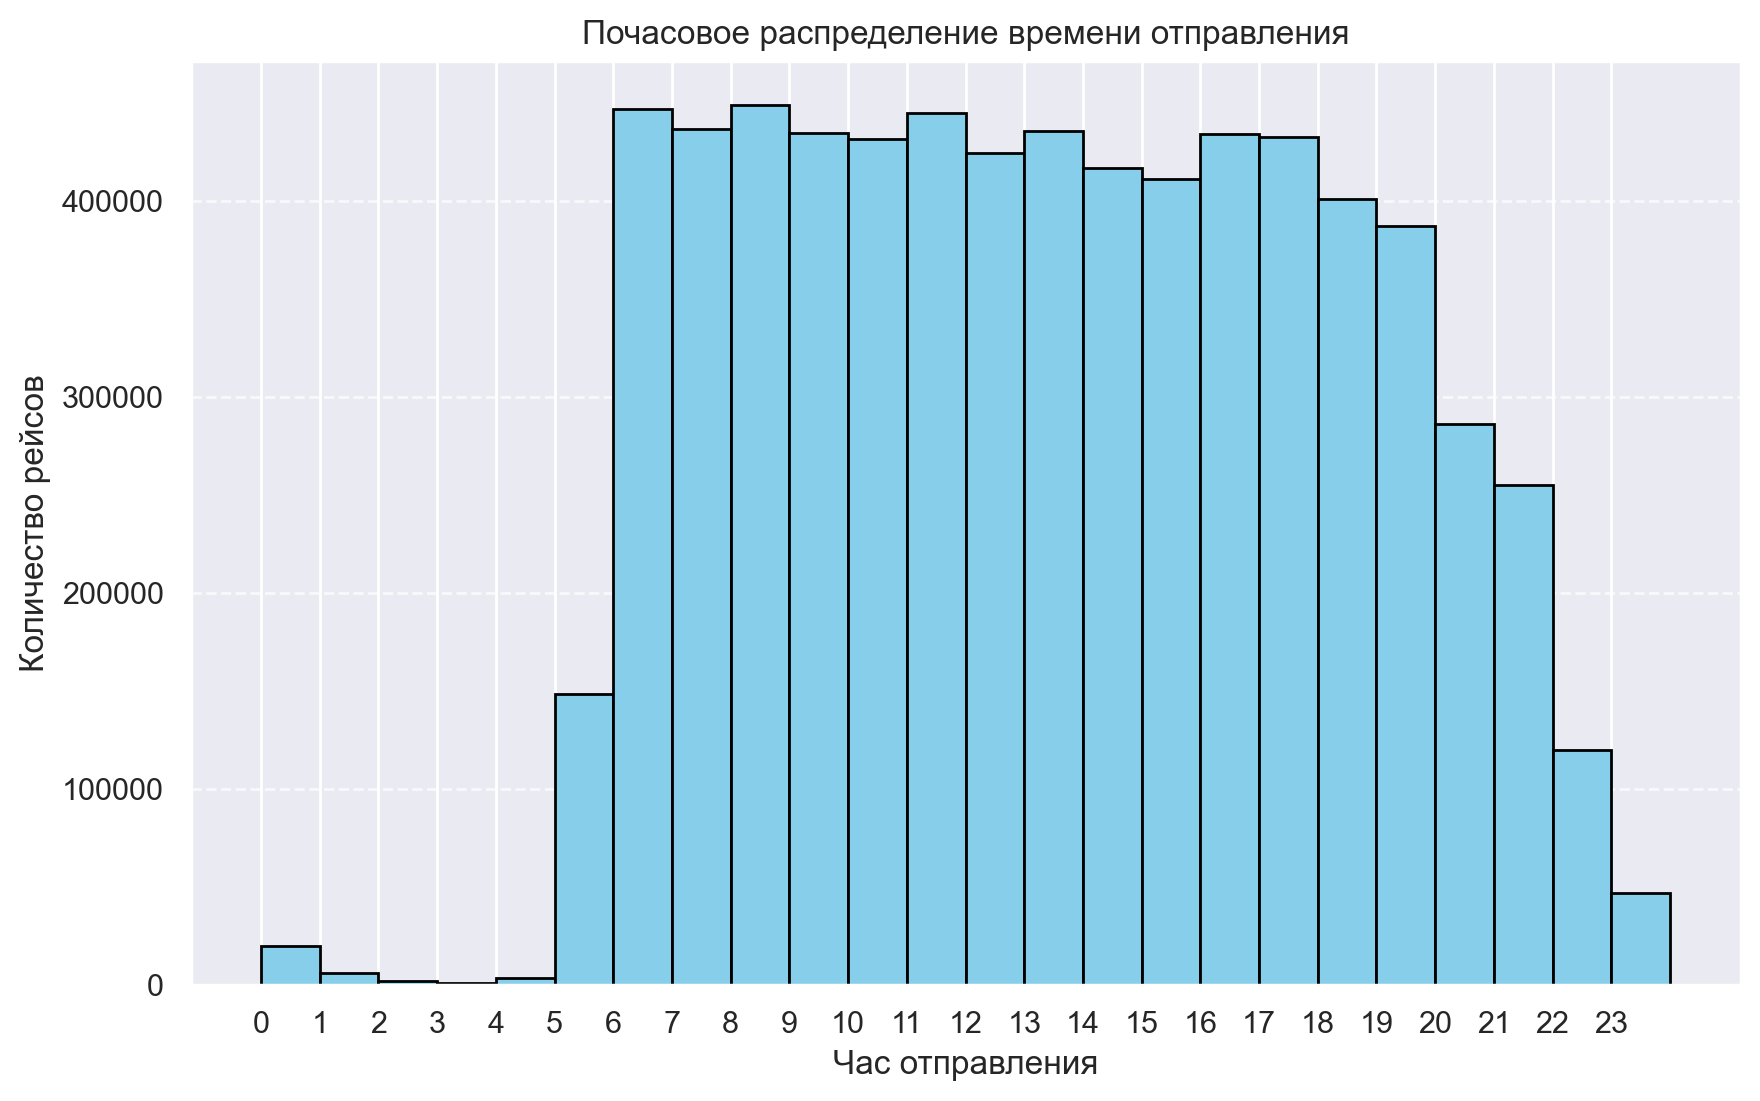

In [51]:
# Вопрос 14. Изучите почасовое распределение времени отправления. Выберите все верные утверждения:**
# В период с 0 до 4 утра рейсов значительно меньше, чем с 19:00 до 20:00.

df['DepHour'] = df['DepTime'].dropna().apply(lambda x: int(str(int(x)).zfill(4)[:2]) if not pd.isnull(x) else np.nan)
plt.figure(figsize=(10, 6))
df['DepHour'].plot(kind='hist', bins=24, color='skyblue', edgecolor='black')
plt.title('Почасовое распределение времени отправления')
plt.xlabel('Час отправления')
plt.ylabel('Количество рейсов')
plt.xticks(range(0, 24))
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

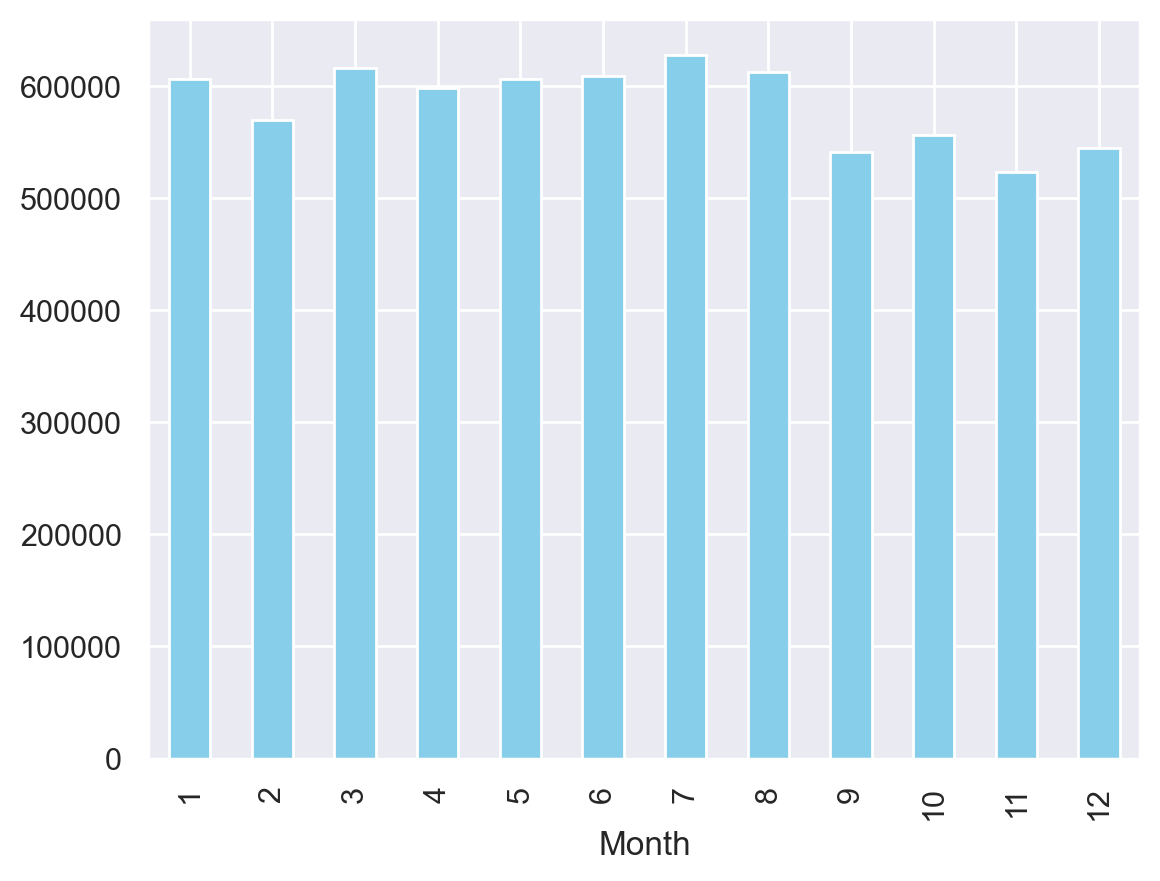

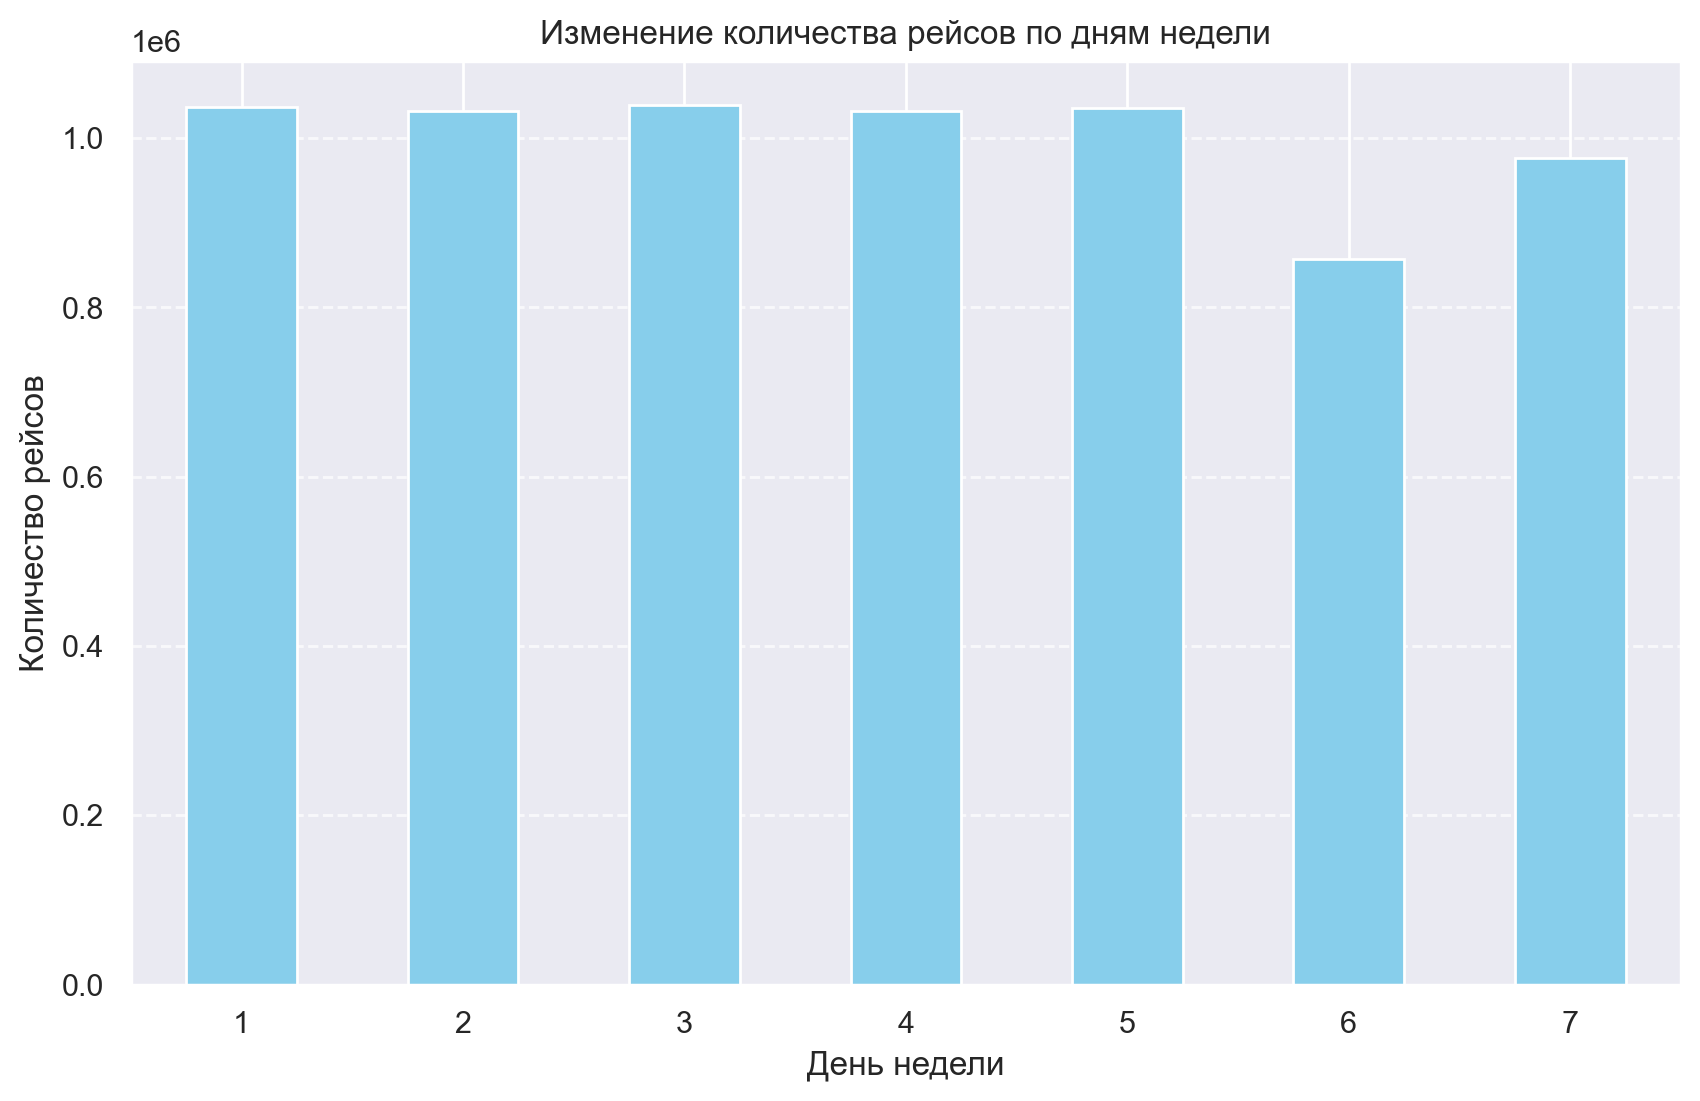

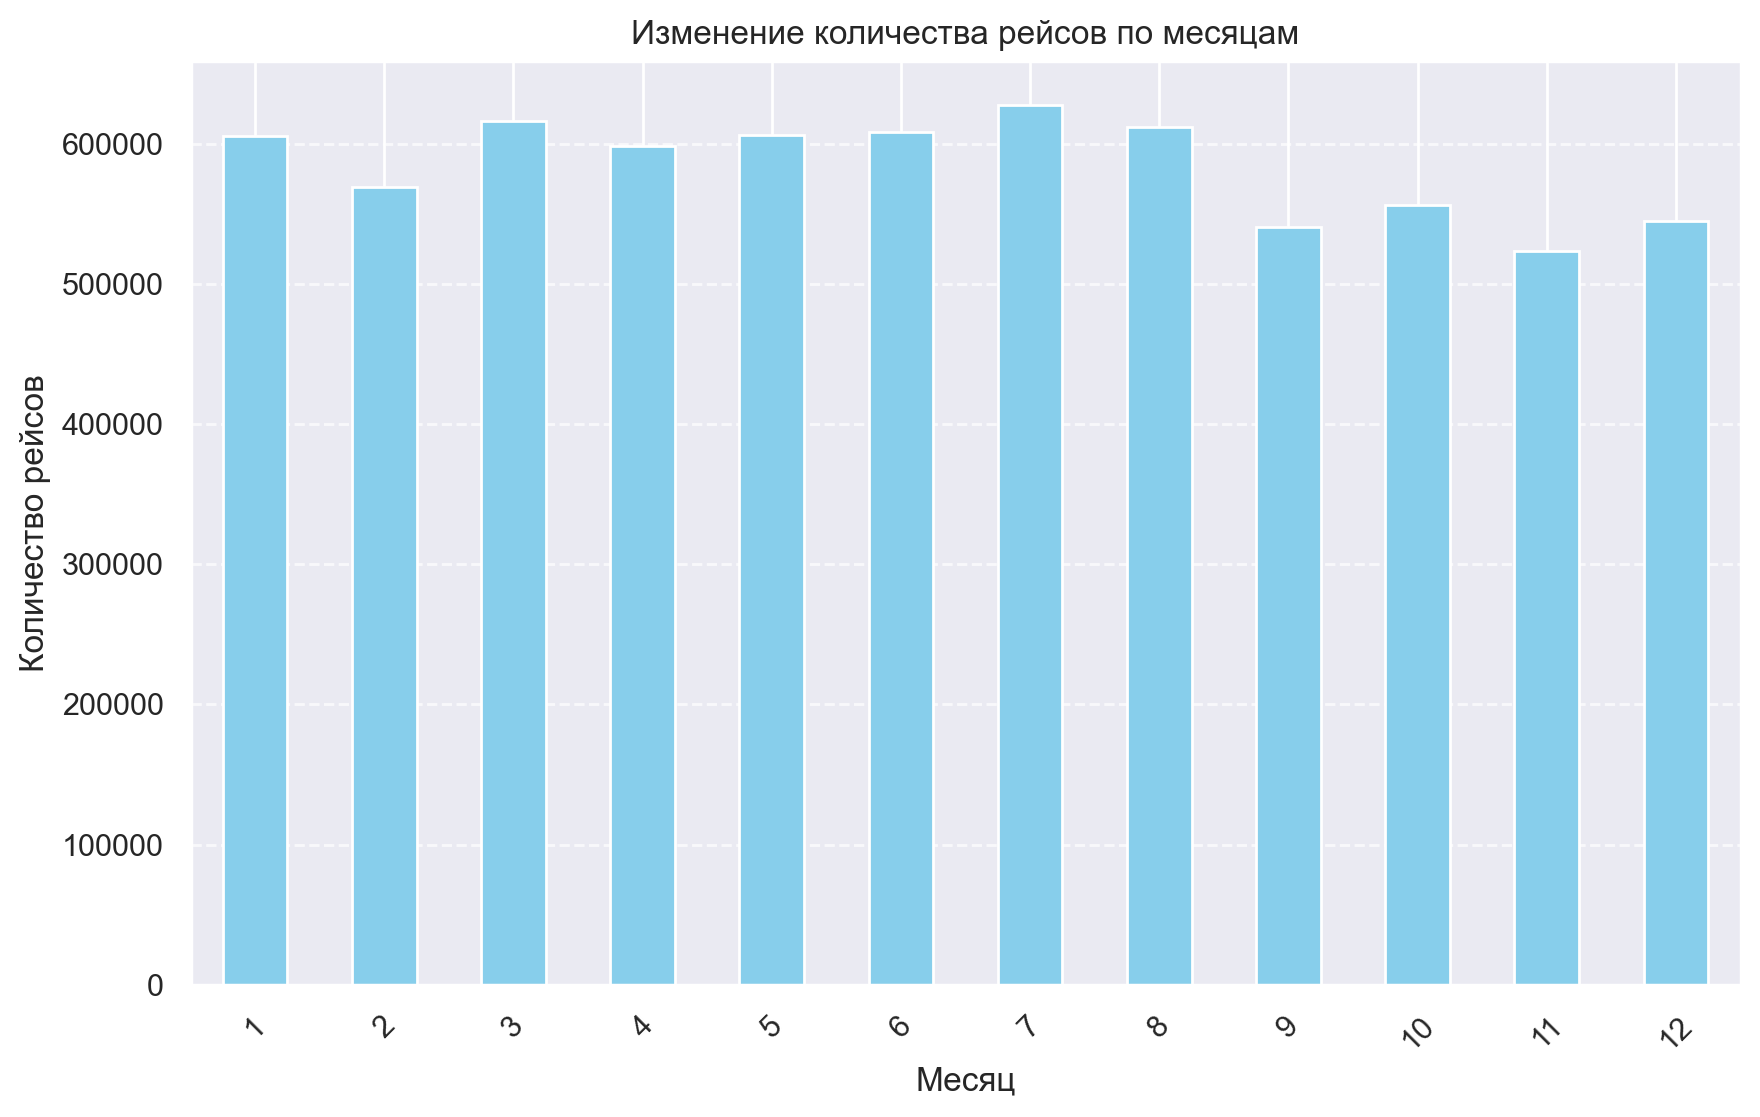

In [52]:
# Вопрос 15. Покажите, как количество рейсов меняется со временем (ежедневно/еженедельно/ежемесячно) и интерпретируйте полученные результаты.**
# Выберите все правильные утверждения:**
# Количество рейсов в выходные дни меньше, чем в будние (рабочие дни).
# Зимой рейсов меньше, чем летом.
# Подсказка*: ищите официальные метеорологические зимние месяцы для Северного полушария.

df['Month'].value_counts().sort_index().plot(kind='bar', color='skyblue')

plt.figure(figsize=(10, 6))
df.groupby('DayOfWeek').size().plot(kind='bar', color='skyblue')
plt.title('Изменение количества рейсов по дням недели')
plt.xlabel('День недели')
plt.ylabel('Количество рейсов')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

plt.figure(figsize=(10, 6))
df.groupby('Month').size().plot(kind='bar', color='skyblue')
plt.title('Изменение количества рейсов по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество рейсов')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

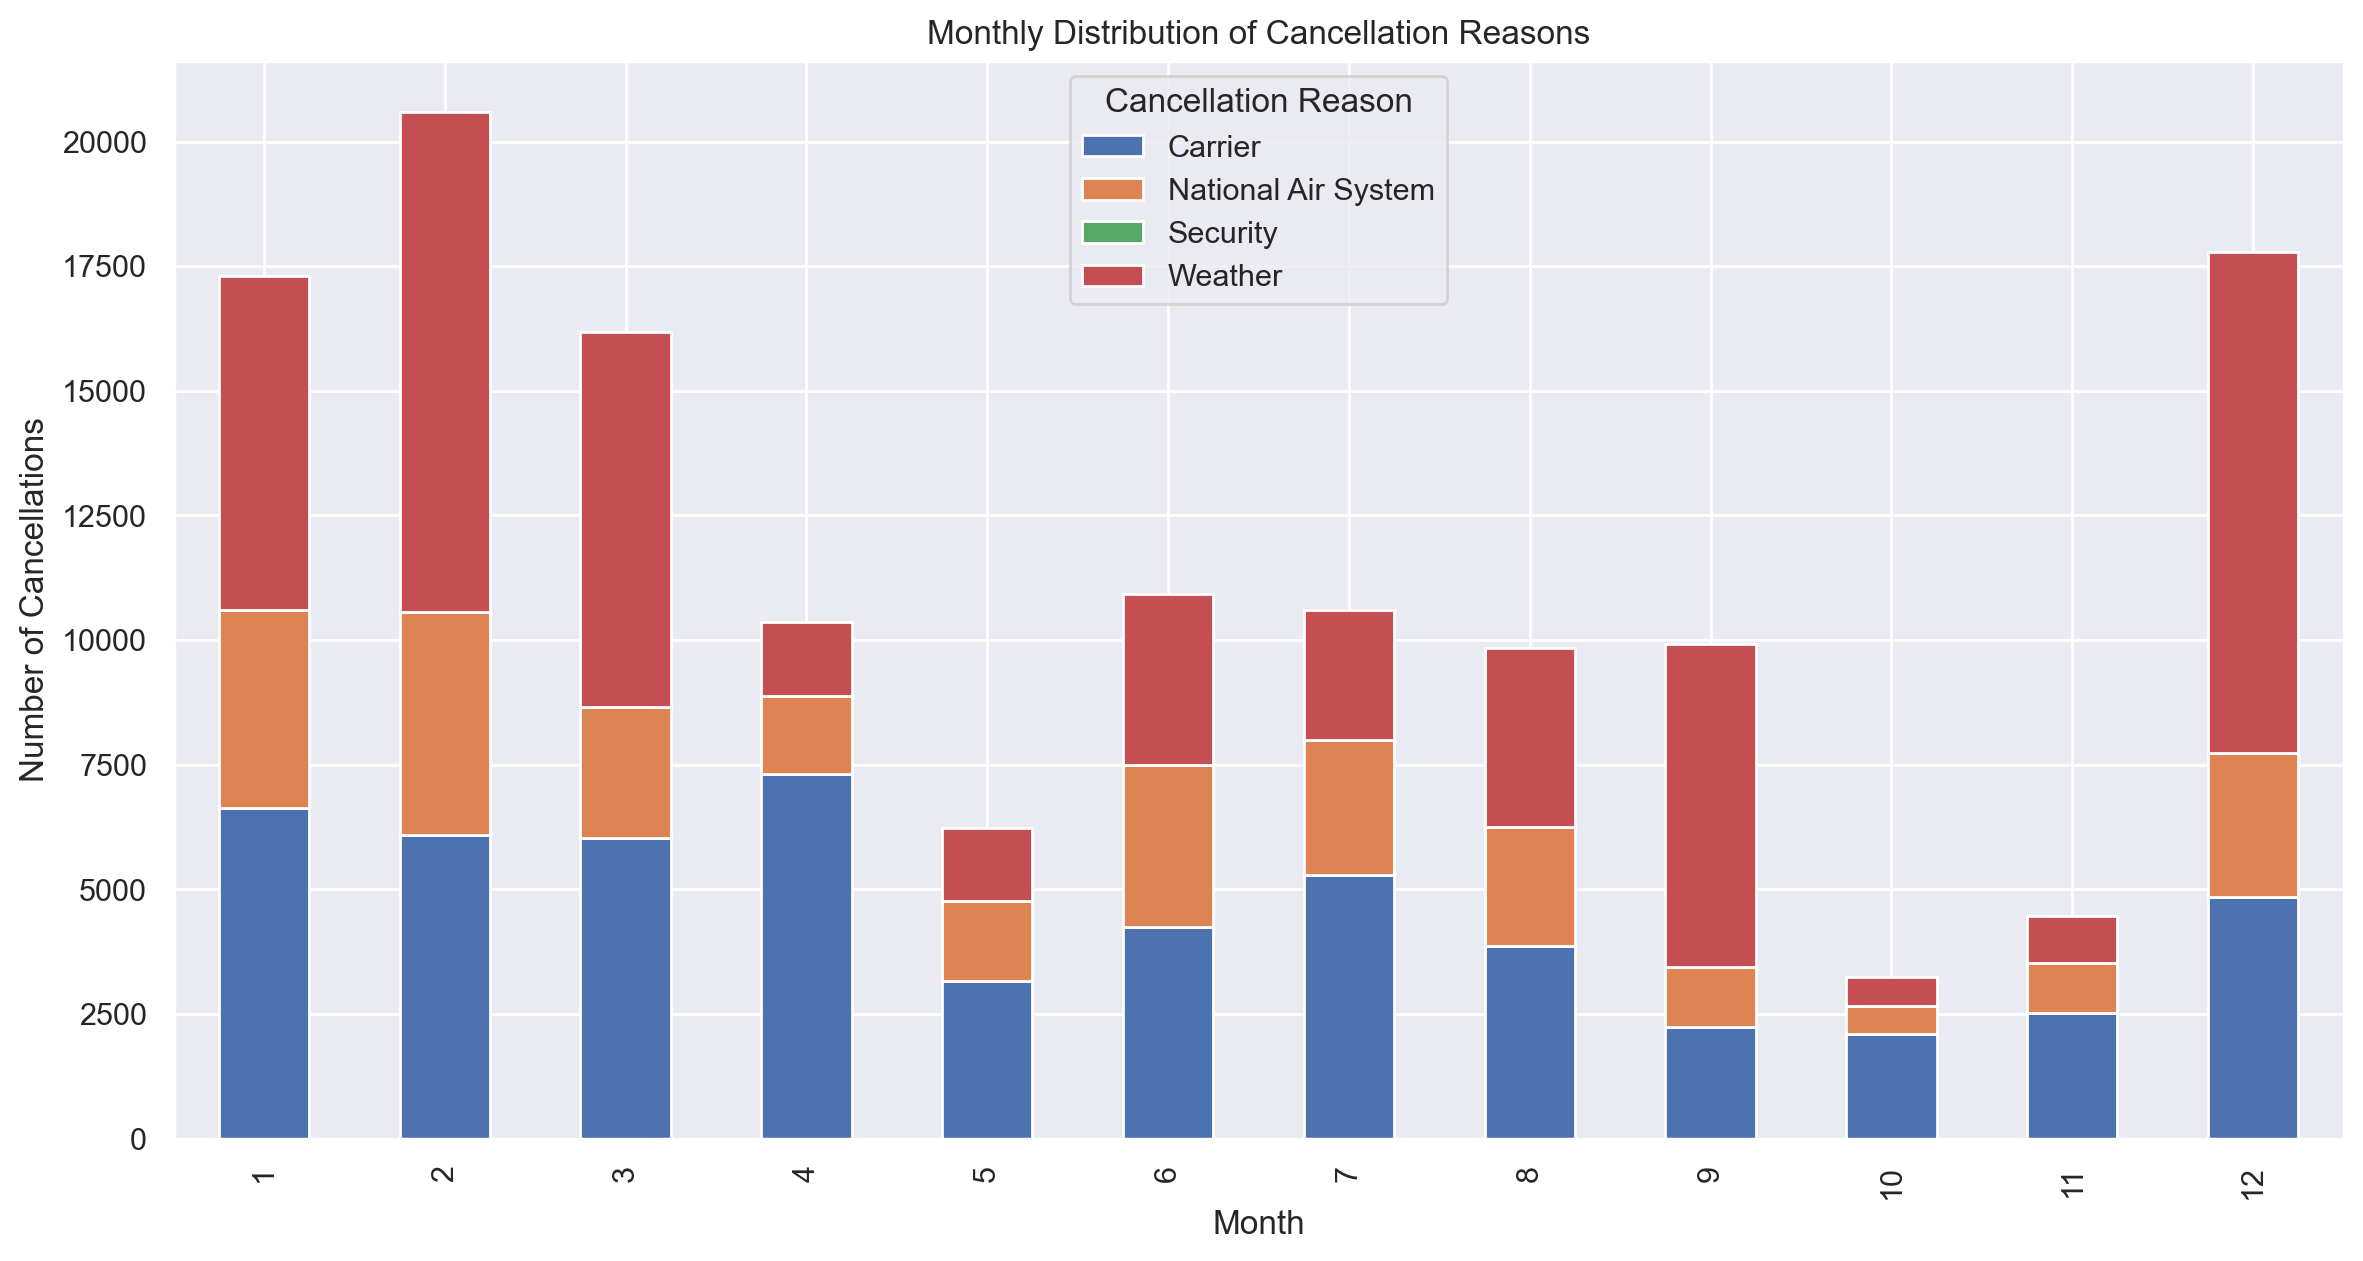

In [53]:
# Вопрос 16. Изучите распределение причин отмены во времени. Составьте диаграмму причин отмены, агрегированных по месяцам.**
# Выберите все правильные утверждения:**
# В октябре наименьшее количество отмен из-за погоды.
# Наибольшее количество отмен в сентябре связано с соображениями безопасности.
# Основная причина отмены рейсов в апреле – операторы связи.

import matplotlib.pyplot as plt
import pandas as pd

cancellation_descriptions = {
    'A': 'Carrier',
    'B': 'Weather',
    'C': 'National Air System',
    'D': 'Security'
}

df['CancellationDescription'] = df['CancellationCode'].map(cancellation_descriptions)
monthly_cancellation_counts = df.groupby(['Month', 'CancellationDescription']).size().unstack(fill_value=0)

monthly_cancellation_counts.plot(kind='bar', stacked=True, figsize=(14, 7))
plt.title('Monthly Distribution of Cancellation Reasons')
plt.xlabel('Month')
plt.ylabel('Number of Cancellations')
plt.legend(title='Cancellation Reason')
plt.show()

In [54]:
# Вопрос 17. В каком месяце происходит наибольшее количество отмен по вине Carrier?**
# Апрель

carrier_cancellations = df[df['CancellationCode'] == 'A']
monthly_carrier_cancellations = carrier_cancellations.groupby('Month')['CancellationCode'].count()
max_month_carrier_cancellations = monthly_carrier_cancellations.idxmax()
max_month_carrier_cancellations

4

In [56]:
# Вопрос 18. Определите перевозчика с наибольшим количеством отмен из-за перевозчика в соответствующем месяце из предыдущего вопроса.**
# AA

carrier_cancellations_in_max_month = df[(df['CancellationCode'] == 'A') & (df['Month'] == max_month_carrier_cancellations)]
carrier_with_most_cancellations = carrier_cancellations_in_max_month['UniqueCarrier'].value_counts().idxmax()
print(carrier_with_most_cancellations)

AA
